## **SQDIFF — сума квадратів різниць**
$$R(x,y)=\sum_{i,j}(T(i,j)-P_{x,y}(i,j))^2$$

Ідея проста: порівнюємо кожен піксель шаблону з відповідним пікселем ділянки пошуку та підносимо різницю до квадрата.
- Ідентичні пікселі дають нульову похибку.
- Великі відмінності сильно збільшують оцінку.
- **Чим менше значення, тим краще.**

Нормалізований варіант `TM_SQDIFF_NORMED` зменшує залежність оцінки від абсолютної енергії зображення, але не робить її повністю незалежною від освітлення.
___
## **CCORR — кореляція**
$$R(x,y)=\sum_{i,j}T(i,j)P_{x,y}(i,j)$$

Тут ми множимо відповідні значення пікселів і підсумовуємо їх.

Якщо великі значення шаблону збігаються з великими значеннями ділянки, кореляція зазвичай збільшується.
- `TM_CCORR` — абсолютна кореляція.
- `TM_CCORR_NORMED` — нормалізована кореляція.

Нормалізація допомагає порівнювати ділянки з різною загальною інтенсивністю, але сама по собі не гарантує стійкості до всіх змін освітлення.
___
## **CCOEFF — кореляція після віднімання середнього**
Спочатку центруємо значення пікселів відносно їхнього середнього:
$$T'=T-\overline{T},\qquad P'=P-\overline{P}$$

Потім обчислюємо кореляцію:
$$R(x,y)=\sum_{i,j}T'(i,j)P'_{x,y}(i,j)$$

Нормалізований варіант додатково ділить результат на норму обох центрованих фрагментів.

`TM_CCOEFF_NORMED` часто є хорошим першим вибором для пошуку незмінного за геометрією об'єкта за помірних змін яскравості.

`TM_CCOEFF_NORMED` <i> **може бути проблемним для шаблонів з нульовою дисперсією, наприклад суцільного однотонного фрагмента. Для таких шаблонів результат може бути некоректним або неінформативним.** </i>
___
* `score` — це оцінка метрики, а не ймовірність. Значення 0.95 не означає 95% імовірності правильного виявлення.
* Якщо об'єктів декілька, `minMaxLoc()` поверне лише один найкращий максимум. Для кількох виявлень потрібно шукати локальні максимуми та застосовувати придушення перекриттів (`NMS`).
* Якщо об'єкт має інший розмір, потрібно шукати на декількох масштабах.
* Якщо змінюється поворот, звичайний `matchTemplate()` не забезпечує інваріантності до обертання.

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from core.entities.constants import Paths as p

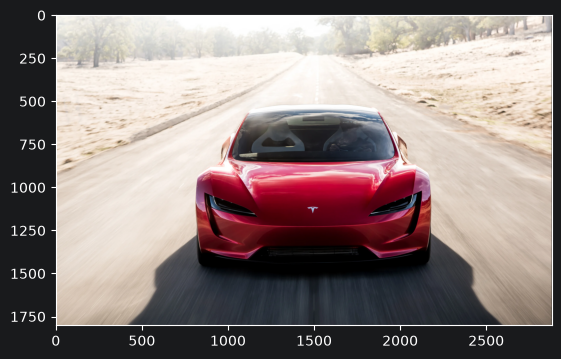

In [2]:
IMAGE_PATH = p.IMAGE_ASSETS / "tesla.png"

img = cv.imread(IMAGE_PATH)

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
plt.figure()
plt.imshow(img_rgb, cmap="gray" )

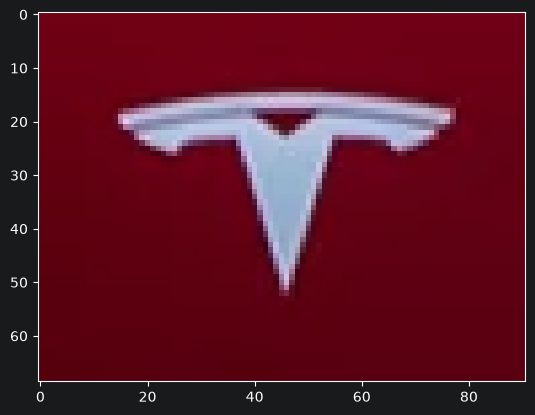

In [4]:
from infrastructure.roi_selector import ROISelector
selector = ROISelector()

roi = selector(img)
logo = img_rgb[roi.y: roi.y + roi.h, roi.x: roi.x + roi.w]

plt.figure()
plt.imshow(logo, cmap="gray")

In [5]:
methods = [cv.TM_CCOEFF,
           cv.TM_CCOEFF_NORMED,
           cv.TM_CCORR,
           cv.TM_CCORR_NORMED,
           cv.TM_SQDIFF,
           cv.TM_SQDIFF_NORMED]

titles = [ "cv.TM_CCOEFF",
           "cv.TM_CCOEFF_NORMED",
           "cv.TM_CCORR",
           "cv.TM_CCORR_NORMED",
           "cv.TM_SQDIFF",
           "cv.TM_SQDIFF_NORMED"]

In [23]:
def match(src: np.ndarray, thickness: int = 2) -> None:
    for i in range(len(methods)):
        src = src.copy()
        template_map = cv.matchTemplate(src, logo, methods[i])
        _, _, min_loc, max_loc = cv.minMaxLoc(template_map)

        if methods[i] == cv.TM_SQDIFF or methods[i] == cv.TM_SQDIFF_NORMED:
            top_left = min_loc
        else:
            top_left = max_loc

        bottom_right = (top_left[0] + roi.w, top_left[1] + roi.h)
        cv.rectangle(src, top_left, bottom_right, (0, 255, 0), thickness)

        plt.figure()
        plt.title(titles[i])
        plt.subplot(121)
        plt.axis('off')
        plt.imshow(template_map)

        plt.subplot(122)
        plt.axis('off')
        plt.imshow(src)

        # plt.show()


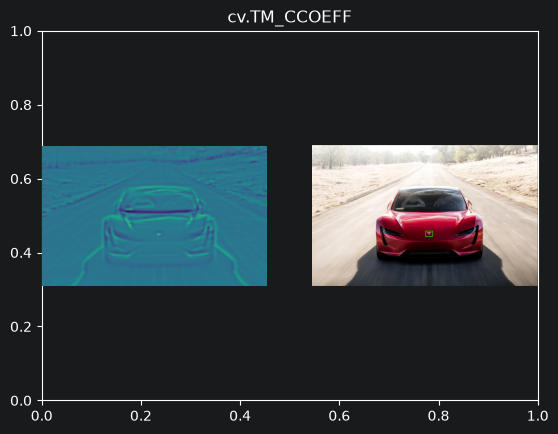

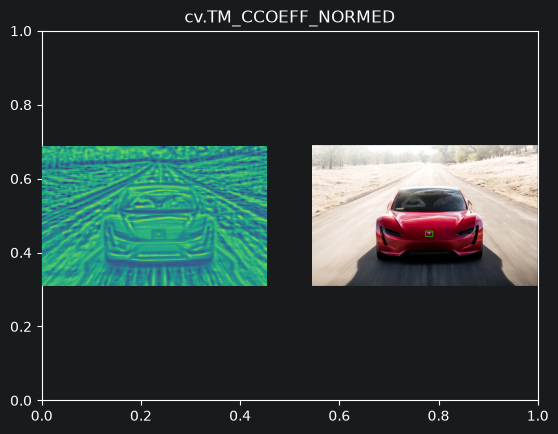

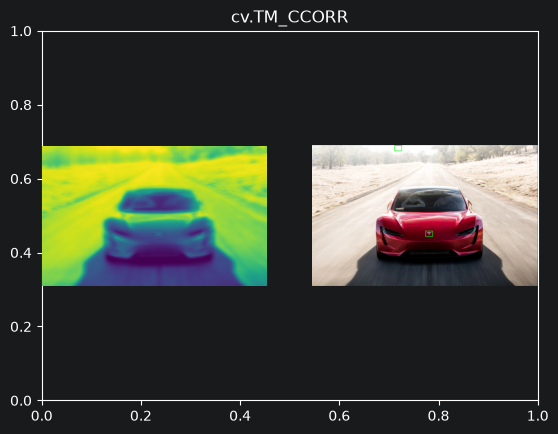

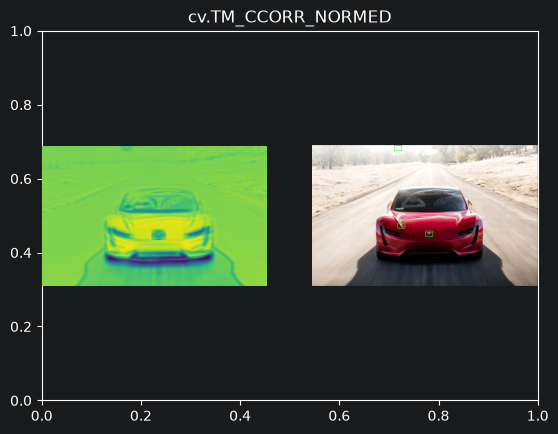

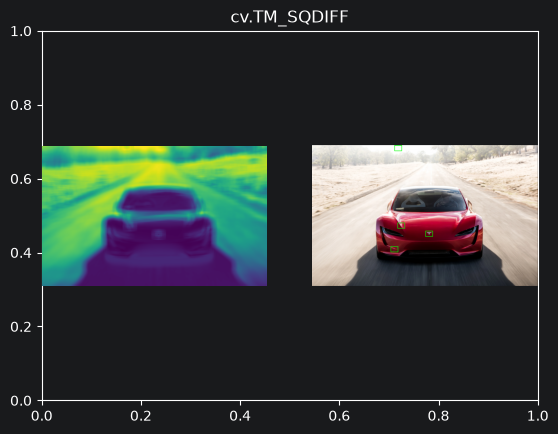

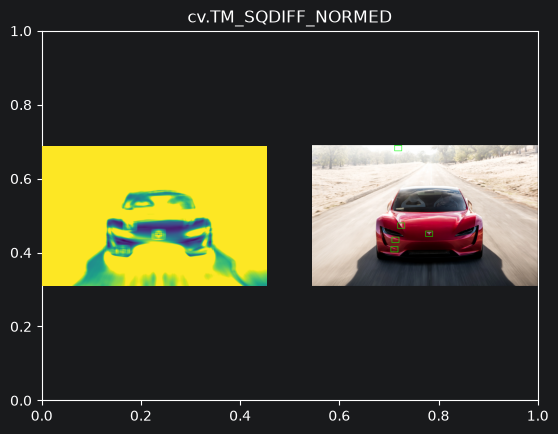

In [24]:
match(img_rgb, thickness=5)

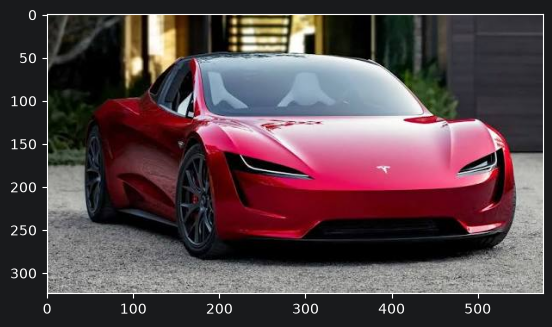

In [14]:
tesla_path = p.IMAGE_ASSETS / "tesla2.jpeg"

tesla = cv.imread(tesla_path, cv.IMREAD_COLOR_RGB)
plt.figure()
plt.imshow(tesla)

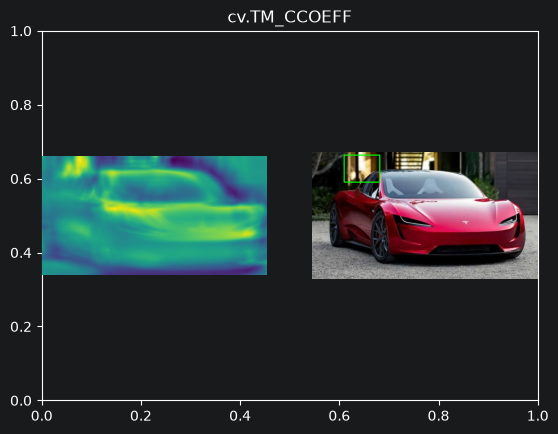

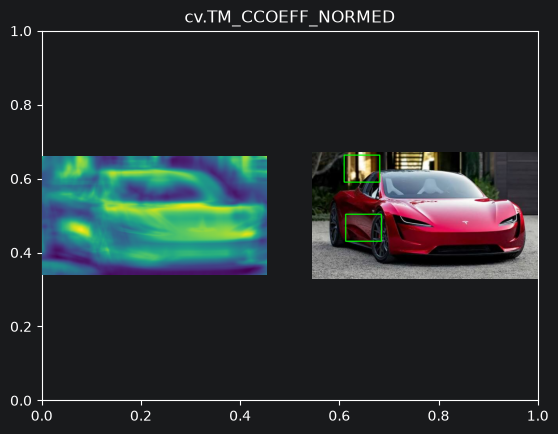

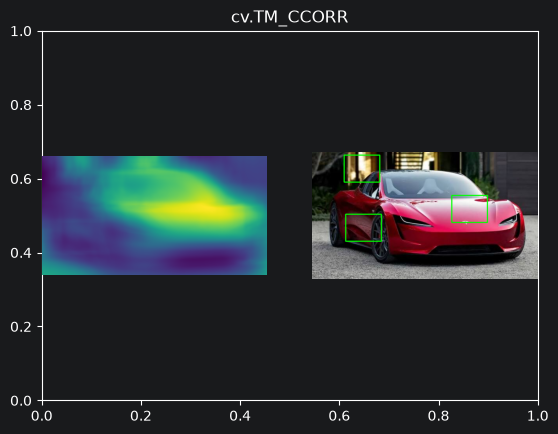

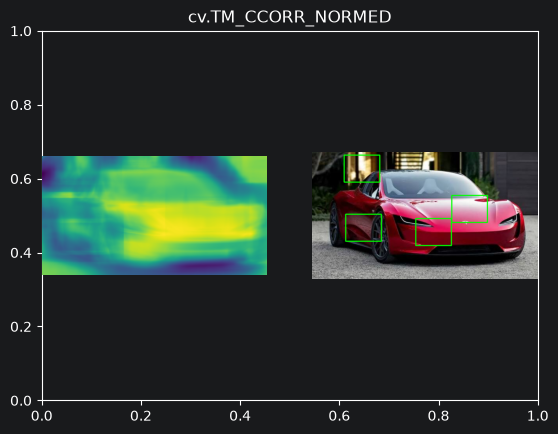

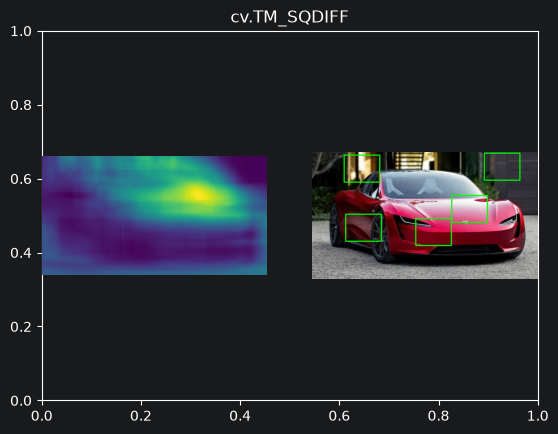

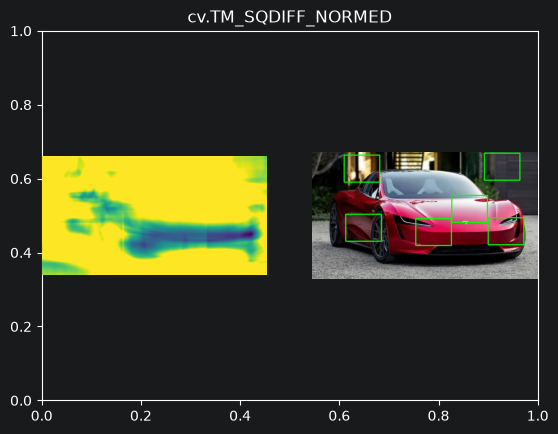

In [15]:
match(tesla)

In [20]:
scale_width = img_rgb.shape[1] / tesla.shape[1]
scale_height = img_rgb.shape[0] / tesla.shape[0]

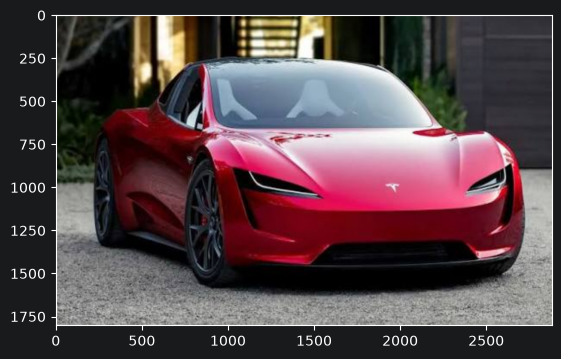

In [21]:

h, w, _ = tesla.shape

tesla_resized = cv.resize(tesla, (int(w * scale_width), int(h * scale_height)))
plt.figure()
plt.imshow(tesla_resized)

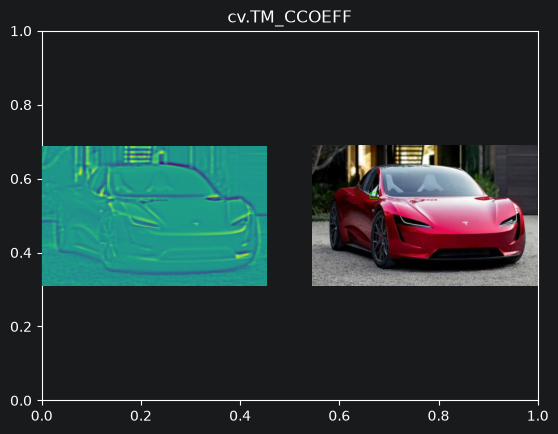

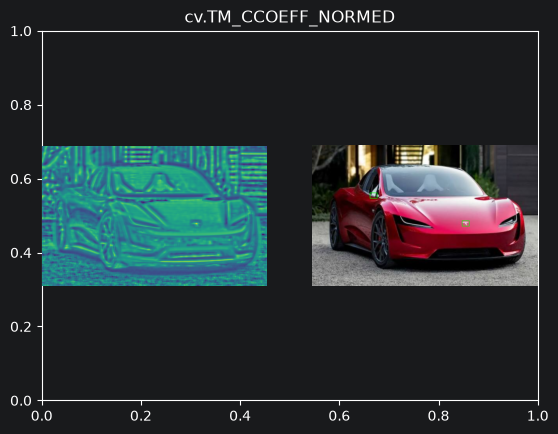

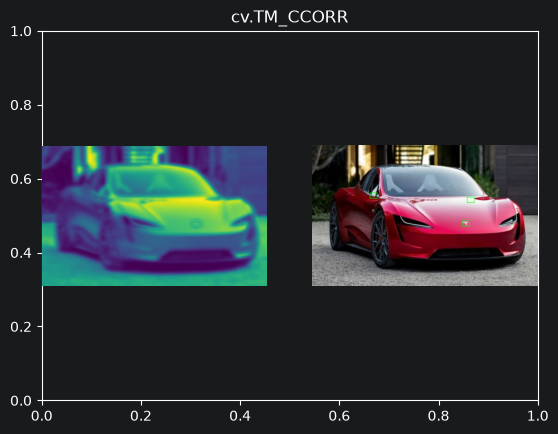

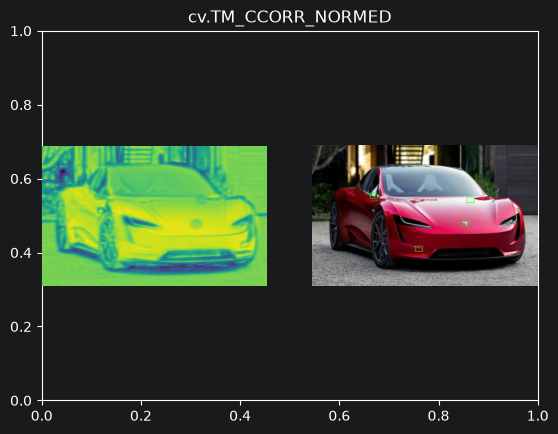

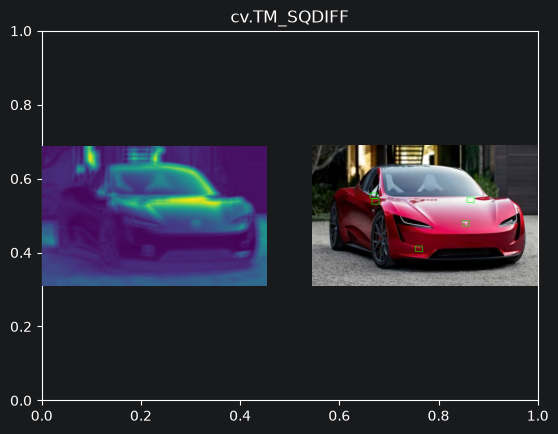

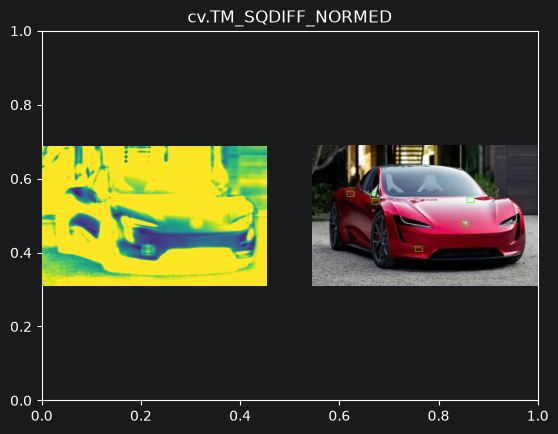

In [25]:
match(tesla_resized, thickness=5)